# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

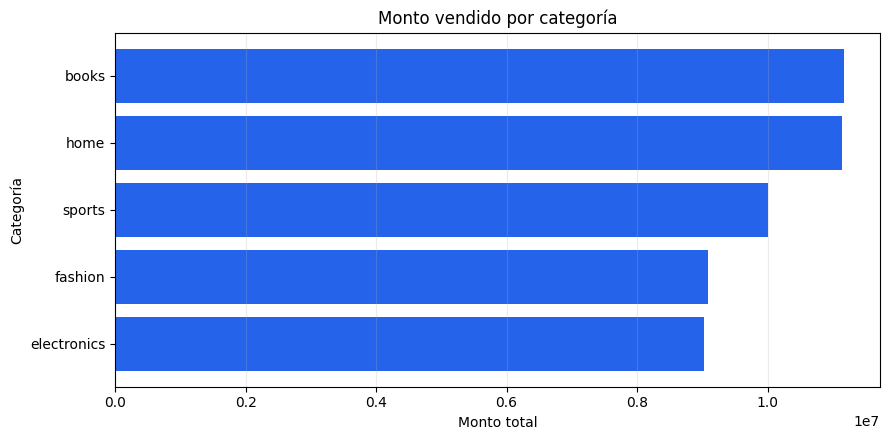

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

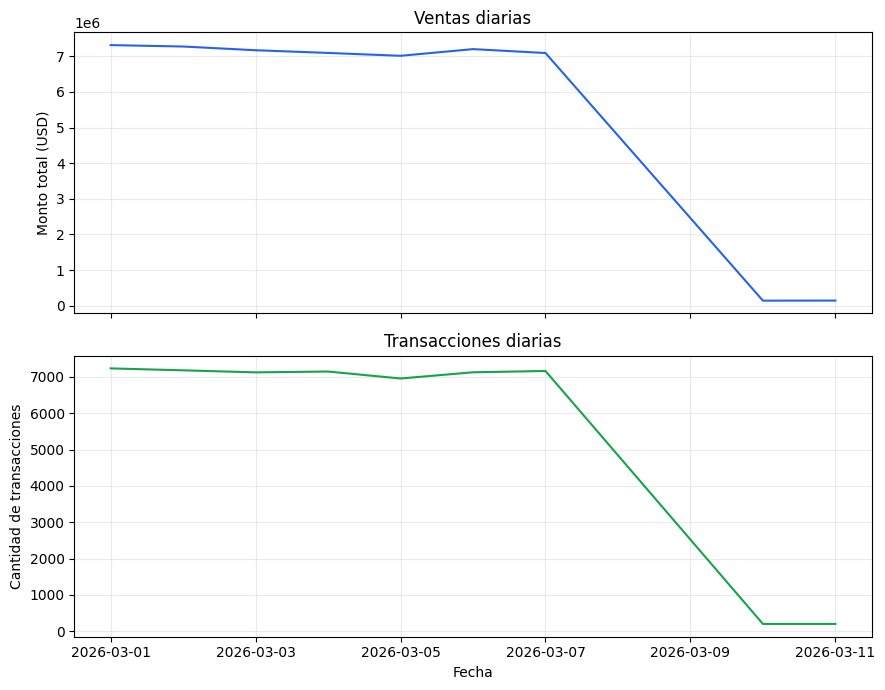

Fecha con mayor monto vendido: 2026-03-01  (Monto: 7,310,840.77, Transacciones: 7,236)
Fecha con mayor cantidad de transacciones: 2026-03-01  (Monto: 7,310,840.77, Transacciones: 7,236)
¿Coinciden? Sí.

Conclusión: Ambos máximos cayeron el 2026-03-01, con un ticket promedio de $1,010.34, comparado con $1,000.17 en el resto de los días. Ese día combinó alto volumen y tickets elevados.


In [0]:
# # Tu solución. Agregá por sale_date antes de convertir el resultado a Pandas.
# Incluí título, ejes, unidades y una respuesta escrita.

daily_amount = (
    spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").alias("total_amount"),
        F.sum("transaction_count").alias("transaction_count"),
    )
)

plot_data = daily_amount.toPandas().sort_values("sale_date")
fecha_max_sales = plot_data.loc[plot_data["total_amount"].idxmax(), "sale_date"]
fecha_max_transactions = plot_data.loc[plot_data["transaction_count"].idxmax(), "sale_date"]

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(plot_data["sale_date"], plot_data["total_amount"], color="#2563eb")
axes[0].set_title("Ventas diarias")
axes[0].set_ylabel("Monto total (USD)")
axes[0].grid(alpha=0.25)

axes[1].plot(plot_data["sale_date"], plot_data["transaction_count"], color="#16a34a")
axes[1].set_title("Transacciones diarias")
axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Cantidad de transacciones")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

max_ventas = plot_data.loc[plot_data["total_amount"].idxmax()]
max_txn = plot_data.loc[plot_data["transaction_count"].idxmax()]
coinciden = fecha_max_sales == fecha_max_transactions

ticket_promedio_max_ventas = max_ventas["total_amount"] / max_ventas["transaction_count"]
ticket_promedio_max_txn = max_txn["total_amount"] / max_txn["transaction_count"]

# Calcular ticket promedio del resto de los días (excluyendo el día de máximo monto)
ticket_promedio_resto = plot_data[plot_data["sale_date"] != fecha_max_sales]["total_amount"].sum() / plot_data[plot_data["sale_date"] != fecha_max_sales]["transaction_count"].sum()

print(f"Fecha con mayor monto vendido: {fecha_max_sales}  (Monto: {max_ventas['total_amount']:,.2f}, Transacciones: {max_ventas['transaction_count']:,})")
print(f"Fecha con mayor cantidad de transacciones: {fecha_max_transactions}  (Monto: {max_txn['total_amount']:,.2f}, Transacciones: {max_txn['transaction_count']:,})")
print(f"¿Coinciden? {'Sí' if coinciden else 'No'}.")
print()
if coinciden:
    print(f"Conclusión: Ambos máximos cayeron el {fecha_max_sales}, con un ticket promedio de ${ticket_promedio_max_ventas:,.2f}, comparado con ${ticket_promedio_resto:,.2f} en el resto de los días. Ese día combinó alto volumen y tickets elevados.")
else:
    print(f"Conclusión: No coinciden. El día de mayor monto ({fecha_max_sales}) tuvo un ticket promedio de ${ticket_promedio_max_ventas:,.2f}, mientras que el de más transacciones ({fecha_max_transactions}) tuvo ${ticket_promedio_max_txn:,.2f}. El ticket promedio del resto de los días fue ${ticket_promedio_resto:,.2f}, lo que muestra que el pico de ventas se explica por tickets más grandes, no por más transacciones.")

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

payment_channel,transaction_count,fraud_transactions,fraud_rate
transfer,16723,2327,0.1391496741015368
wallet,16724,2169,0.1296938531451806
card,16902,2119,0.12536977872441132


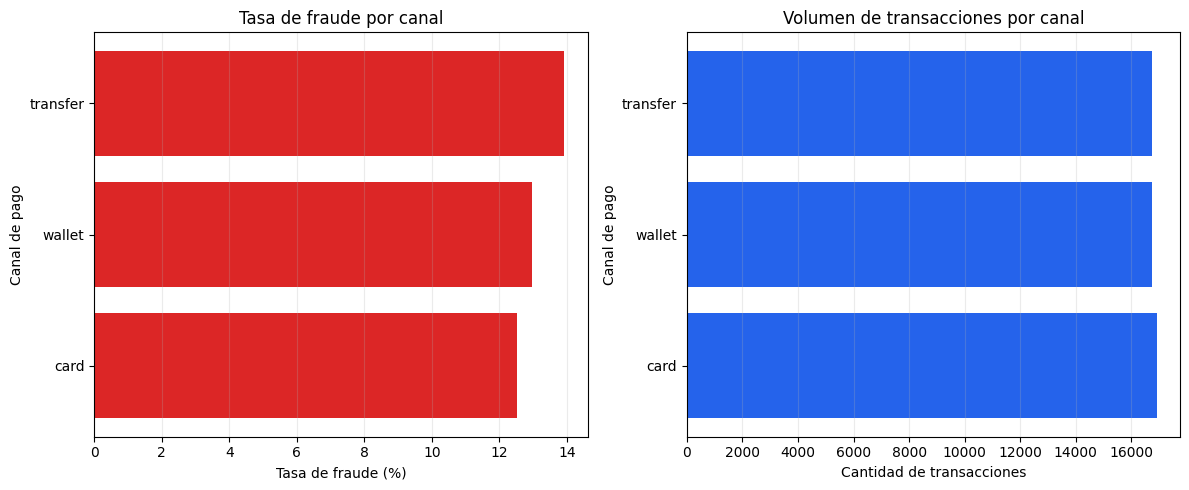

Respuesta: transfer es el canal con mayor tasa de fraude (13.91%).

Ese canal procesó 16,723 transacciones (33.2% del total 50,349).
La tasa global de fraude es 13.14%.

Conclusión: transfer no sólo tiene la mayor tasa de fraude sino también un volumen representativo
(33.2% del total), por lo que la conclusión se sostiene al considerar el número de transacciones.


In [0]:
# Consigna 2 — Canal y fraude
# Tasa de fraude por canal = suma(fraud_transactions) / suma(transaction_count)
# No promediar fraud_rate directamente: recalcular el denominador a partir de los totales.

channel_fraud = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("transaction_count").alias("transaction_count"),
        F.sum("fraud_transactions").alias("fraud_transactions"),
    )
    .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transaction_count"))
    .orderBy(F.desc("fraud_rate")))

channel_fraud.display()

plot_data = channel_fraud.toPandas().sort_values("fraud_rate", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Tasa de fraude por canal
axes[0].barh(plot_data["payment_channel"], plot_data["fraud_rate"] * 100, color="#dc2626")
axes[0].set_title("Tasa de fraude por canal")
axes[0].set_xlabel("Tasa de fraude (%)")
axes[0].set_ylabel("Canal de pago")
axes[0].grid(axis="x", alpha=0.25)

# Volumen de transacciones por canal
axes[1].barh(plot_data["payment_channel"], plot_data["transaction_count"], color="#2563eb")
axes[1].set_title("Volumen de transacciones por canal")
axes[1].set_xlabel("Cantidad de transacciones")
axes[1].set_ylabel("Canal de pago")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

leader = channel_fraud.first()
total_txn = channel_fraud.agg(F.sum("transaction_count").alias("t")).first()["t"]
total_fraud = channel_fraud.agg(F.sum("fraud_transactions").alias("f")).first()["f"]
global_rate = total_fraud / total_txn

max_channel = leader.payment_channel
max_rate = leader.fraud_rate
max_txn = leader.transaction_count

# Proporción del volumen total que representa el canal con mayor tasa
share_volume = max_txn / total_txn

print(f"Respuesta: {max_channel} es el canal con mayor tasa de fraude ({max_rate*100:.2f}%).")
print()
print(f"Ese canal procesó {max_txn:,} transacciones ({share_volume*100:.1f}% del total {total_txn:,}).")
print(f"La tasa global de fraude es {global_rate*100:.2f}%.")
print()
if share_volume < 0.10:
    print(f"Conclusión: aunque {max_channel} presenta la mayor tasa, su volumen es bajo ({share_volume*100:.1f}% del total),")
    print("por lo que la conclusión debe tomarse con cautela: pocos casos pueden inflar la tasa.")
else:
    print(f"Conclusión: {max_channel} no sólo tiene la mayor tasa de fraude sino también un volumen representativo")
    print(f"({share_volume*100:.1f}% del total), por lo que la conclusión se sostiene al considerar el número de transacciones.")

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

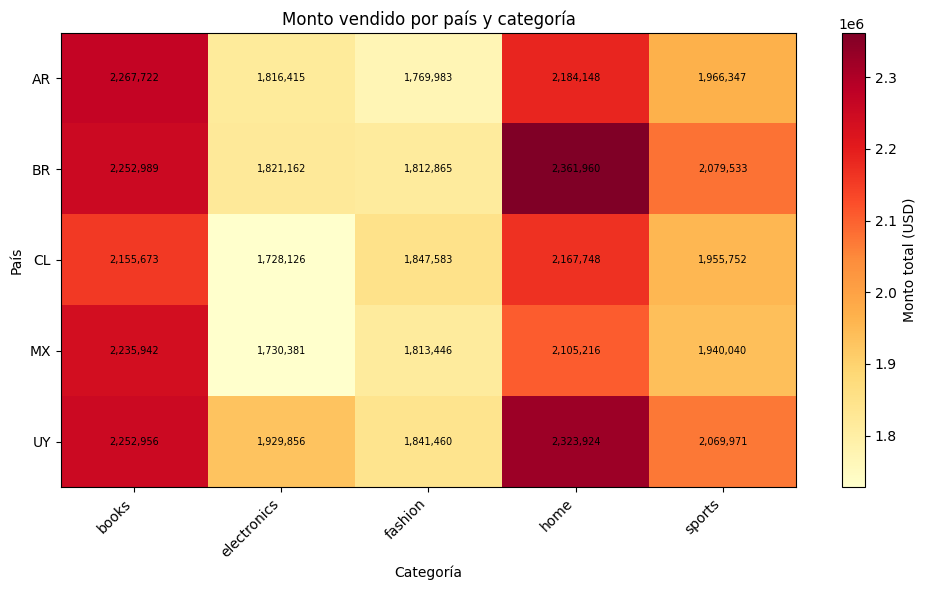

Respuesta: BR + home es la combinación con mayor monto vendido (2,361,959.97).

Categoría dominante por país:
  AR: books (2,267,722.26)
  BR: home (2,361,959.97)
  CL: home (2,167,748.03)
  MX: books (2,235,941.63)
  UY: home (2,323,924.46)

Conclusión: la categoría dominante cambia según el mercado (se encontraron 2 categorías distintas como líderes). No existe una única categoría dominante en todos los países; las preferencias varían geográficamente.


In [0]:
# Tu solución. Algunas opciones: mapa de calor o barras agrupadas.
# La conclusión debe mencionar tanto el máximo global como las diferencias entre países.

# Consigna 3 — Concentración geográfica y de producto
# Mapa de calor: permite comparar simultáneamente países (filas) y categorías (columnas)
# en una sola matriz de color. Es más legible que barras agrupadas cuando hay muchas
# combinaciones, porque el color codifica el monto y la posición codifica las dos dimensiones.

country_category = (spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy("country", "category"))

plot_data = country_category.toPandas()
heatmap_data = plot_data.pivot(index="country", columns="category", values="total_amount").fillna(0).astype(float)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heatmap_data.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_title("Monto vendido por país y categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("País")
fig.colorbar(im, ax=ax, label="Monto total (USD)")

# Anotar cada celda con su valor
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.values[i, j]
        ax.text(j, i, f"{value:,.0f}", ha="center", va="center", fontsize=7)

fig.tight_layout()
plt.show()

# Máximo global: combinación país-categoría con mayor monto
global_max = country_category.orderBy(F.desc("total_amount")).first()

# Categoría dominante por país
from pyspark.sql.window import Window

w = Window.partitionBy("country").orderBy(F.desc("total_amount"))
top_per_country = (country_category
    .withColumn("rn", F.row_number().over(w))
    .filter(F.col("rn") == 1)
    .drop("rn")
    .orderBy("country"))

top_per_country_pd = top_per_country.toPandas()
dominant_categories = top_per_country_pd["category"].unique()

print(f"Respuesta: {global_max.country} + {global_max.category} es la combinación con mayor monto vendido ({global_max.total_amount:,.2f}).")
print()
print("Categoría dominante por país:")
for _, row in top_per_country_pd.iterrows():
    print(f"  {row['country']}: {row['category']} ({row['total_amount']:,.2f})")
print()
if len(dominant_categories) == 1:
    print(f"Conclusión: {dominant_categories[0]} domina en todos los países, lo que indica una categoría fuertemente líder a nivel global.")
else:
    print(f"Conclusión: la categoría dominante cambia según el mercado (se encontraron {len(dominant_categories)} categorías distintas como líderes). No existe una única categoría dominante en todos los países; las preferencias varían geográficamente.")


## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.

source_batch_id,accepted_transactions,rejected_transactions,total_amount,fraud_transactions,refreshed_at,total_transactions,accepted_pct,rejected_pct
batch_002,200,2,144813.00,27,2026-10-14T15:59:33.644Z,202,99.00990099009901,0.9900990099009901
batch_003,201,2,147014.99,28,2026-10-14T15:59:33.644Z,203,99.01477832512316,0.9852216748768473
initial,49948,51,50139370.34,6560,2026-10-14T15:59:33.644Z,49999,99.8979979599592,0.10200204004080081


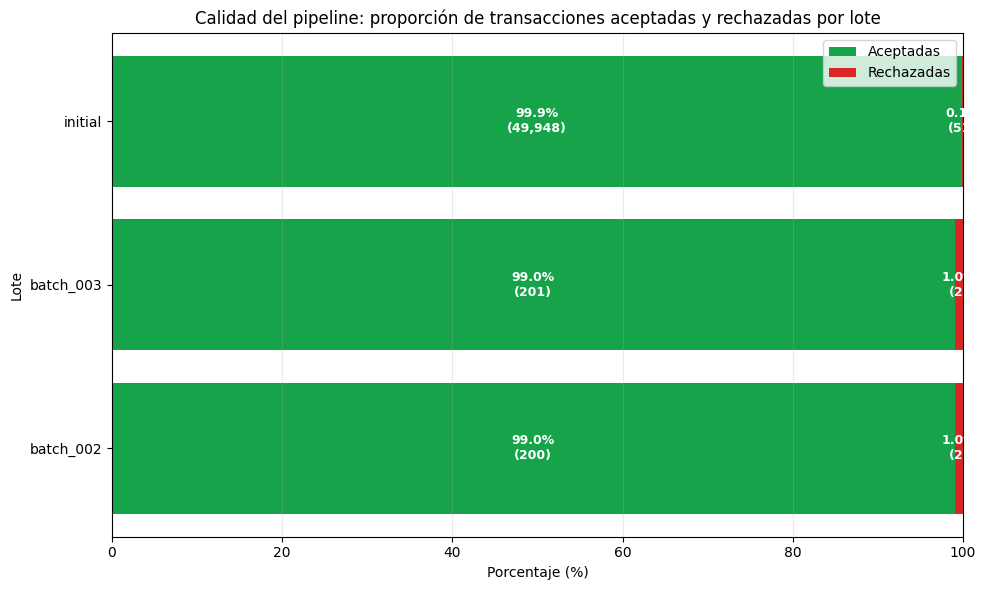

Resumen por lote:
  batch_002: 200 aceptadas / 2 rechazadas (total 202, 99.0% aceptadas).
  batch_003: 201 aceptadas / 2 rechazadas (total 203, 99.0% aceptadas).
  initial: 49,948 aceptadas / 51 rechazadas (total 49,999, 99.9% aceptadas).

Conclusión: Todos los lotes presentan una calidad similar (diferencia de 0.9 puntos porcentuales), pero los tamaños son muy distintos: el más grande tiene 247.5x las transacciones del más chico. Con muestras tan diferentes, la tasa sola no alcanza para evaluar la calidad real.


In [0]:
# Consigna 4 — Calidad del pipeline
# Calculá total = accepted_transactions + rejected_transactions y compará proporciones entre lotes.
# Un gráfico de barras apiladas al 100% facilita comparar la calidad relativa sin que el tamaño domine.

batch_quality = (spark.table(batch)
    .withColumn("total_transactions", F.col("accepted_transactions") + F.col("rejected_transactions"))
    .withColumn("accepted_pct", F.col("accepted_transactions") / F.col("total_transactions") * 100)
    .withColumn("rejected_pct", F.col("rejected_transactions") / F.col("total_transactions") * 100)
    .orderBy("source_batch_id"))

batch_quality.display()

plot_data = batch_quality.toPandas()

# Gráfico de barras 100% apiladas
fig, ax = plt.subplots(figsize=(10, 6))

lotes = plot_data["source_batch_id"]
aceptadas_pct = plot_data["accepted_pct"]
rechazadas_pct = plot_data["rejected_pct"]

# Barras apiladas
ax.barh(lotes, aceptadas_pct, color="#16a34a", label="Aceptadas")
ax.barh(lotes, rechazadas_pct, left=aceptadas_pct, color="#dc2626", label="Rechazadas")

# Anotar porcentajes y cantidades absolutas
for i, row in plot_data.iterrows():
    # Porcentaje y cantidad de aceptadas
    ax.text(row["accepted_pct"] / 2, i, f"{row['accepted_pct']:.1f}%\n({row['accepted_transactions']:,})", 
            ha="center", va="center", fontsize=9, color="white", weight="bold")
    # Porcentaje y cantidad de rechazadas
    ax.text(row["accepted_pct"] + row["rejected_pct"] / 2, i, f"{row['rejected_pct']:.1f}%\n({row['rejected_transactions']:,})", 
            ha="center", va="center", fontsize=9, color="white", weight="bold")

ax.set_xlabel("Porcentaje (%)")
ax.set_ylabel("Lote")
ax.set_title("Calidad del pipeline: proporción de transacciones aceptadas y rechazadas por lote")
ax.set_xlim(0, 100)
ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Resumen de todos los lotes
print("Resumen por lote:")
for _, row in plot_data.iterrows():
    print(f"  {row['source_batch_id']}: {row['accepted_transactions']:,} aceptadas / {row['rejected_transactions']:,} rechazadas "
          f"(total {row['total_transactions']:,}, {row['accepted_pct']:.1f}% aceptadas).")
print()

# Comparar calidad entre todos los lotes
aceptacion_min = plot_data.loc[plot_data["accepted_pct"].idxmin()]
aceptacion_max = plot_data.loc[plot_data["accepted_pct"].idxmax()]
diff_pct = aceptacion_max["accepted_pct"] - aceptacion_min["accepted_pct"]

# Ratio de tamaños para la conclusión
tamanos = plot_data["total_transactions"]
ratio_tamanos = tamanos.max() / tamanos.min()

if abs(diff_pct) < 1:
    print(f"Conclusión: Todos los lotes presentan una calidad similar (diferencia de {diff_pct:.1f} puntos porcentuales), pero los tamaños son muy distintos: el más grande tiene {ratio_tamanos:.1f}x las transacciones del más chico. Con muestras tan diferentes, la tasa sola no alcanza para evaluar la calidad real.")
else:
    print(f"Conclusión: La calidad varía entre lotes ({aceptacion_min['source_batch_id']} con {aceptacion_min['accepted_pct']:.1f}% vs {aceptacion_max['source_batch_id']} con {aceptacion_max['accepted_pct']:.1f}%), pero los tamaños son muy distintos: el más grande tiene {ratio_tamanos:.1f}x las transacciones del más chico. Con muestras tan diferentes, la tasa sola no alcanza para evaluar la calidad real.")

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.